# 03 - Fama-MacBeth characteristic regressions

Monthly cross-sectional OLS of next-month excess returns on characteristic z-scores; HAC inference on the slope means. A significant slope shows predictive association in this sample, not proof of a priced risk factor. |t| > 3 is an illustrative hurdle only.

In [1]:
import logging

import pandas as pd
from IPython.display import Image, display

from factors import pipeline as pl
from factors.data import DataUnavailableError  # noqa: F401 - used by the real-data cells

logging.basicConfig(level=logging.WARNING)
pd.set_option("display.width", 160, "display.max_columns", 20)

def show(ctx, nn, name):
    display(Image(filename=str(ctx.fig(nn, name))))

In [2]:
syn = pl.Context('synthetic', 'fast')
r = pl.stage_fama_macbeth(syn)
r['summary'][['spec', 'term', 'premium_monthly', 't_hac', 'n_months', 'avg_r2', 'passes_t3_hurdle']].round(4)

,spec,term,premium_monthly,t_hac,n_months,avg_r2,passes_t3_hurdle
0,uni_value,const,0.0015,0.3530,98,0.0374,None
1,uni_value,value,0.0002,0.1453,98,0.0374,False
2,uni_value_ind,const,-0.0026,-0.4982,98,0.1718,None
3,uni_value_ind,value,0.0005,0.2731,98,0.1718,False
4,uni_momentum,const,0.0035,0.7987,86,0.0684,None
5,uni_momentum,momentum,-0.0001,-0.0478,86,0.0684,False
6,uni_momentum_ind,const,-0.0013,-0.2338,86,0.1940,None
7,uni_momentum_ind,momentum,0.0001,0.0483,86,0.1940,False
8,uni_low_vol,const,0.0030,0.7241,93,0.0169,None
9,uni_low_vol,low_vol,-0.0004,-0.3387,93,0.0169,False


Cross-check against `linearmodels.FamaMacBeth` on the matched sample (identical point estimates; the Bartlett-kernel SE with bandwidth 4 equals the HAC(4) SE with the T/(T-1) correction).

In [3]:
r['lm']

,params,se_unadjusted,se_kernel,own_params,own_se_hac_L4,own_se_unadjusted,max_abs_param_diff
const,0.003483,0.004719,0.004449,0.003483,0.004449,0.004719,8.673617e-18
value,-0.001371,0.001748,0.001696,-0.001371,0.001696,0.001748,8.673617e-18
momentum,-0.000992,0.002541,0.002547,-0.000992,0.002547,0.002541,8.673617e-18
low_vol,-0.000635,0.001252,0.001232,-0.000635,0.001232,0.001252,8.673617e-18
quality,0.002215,0.001495,0.001671,0.002215,0.001671,0.001495,8.673617e-18


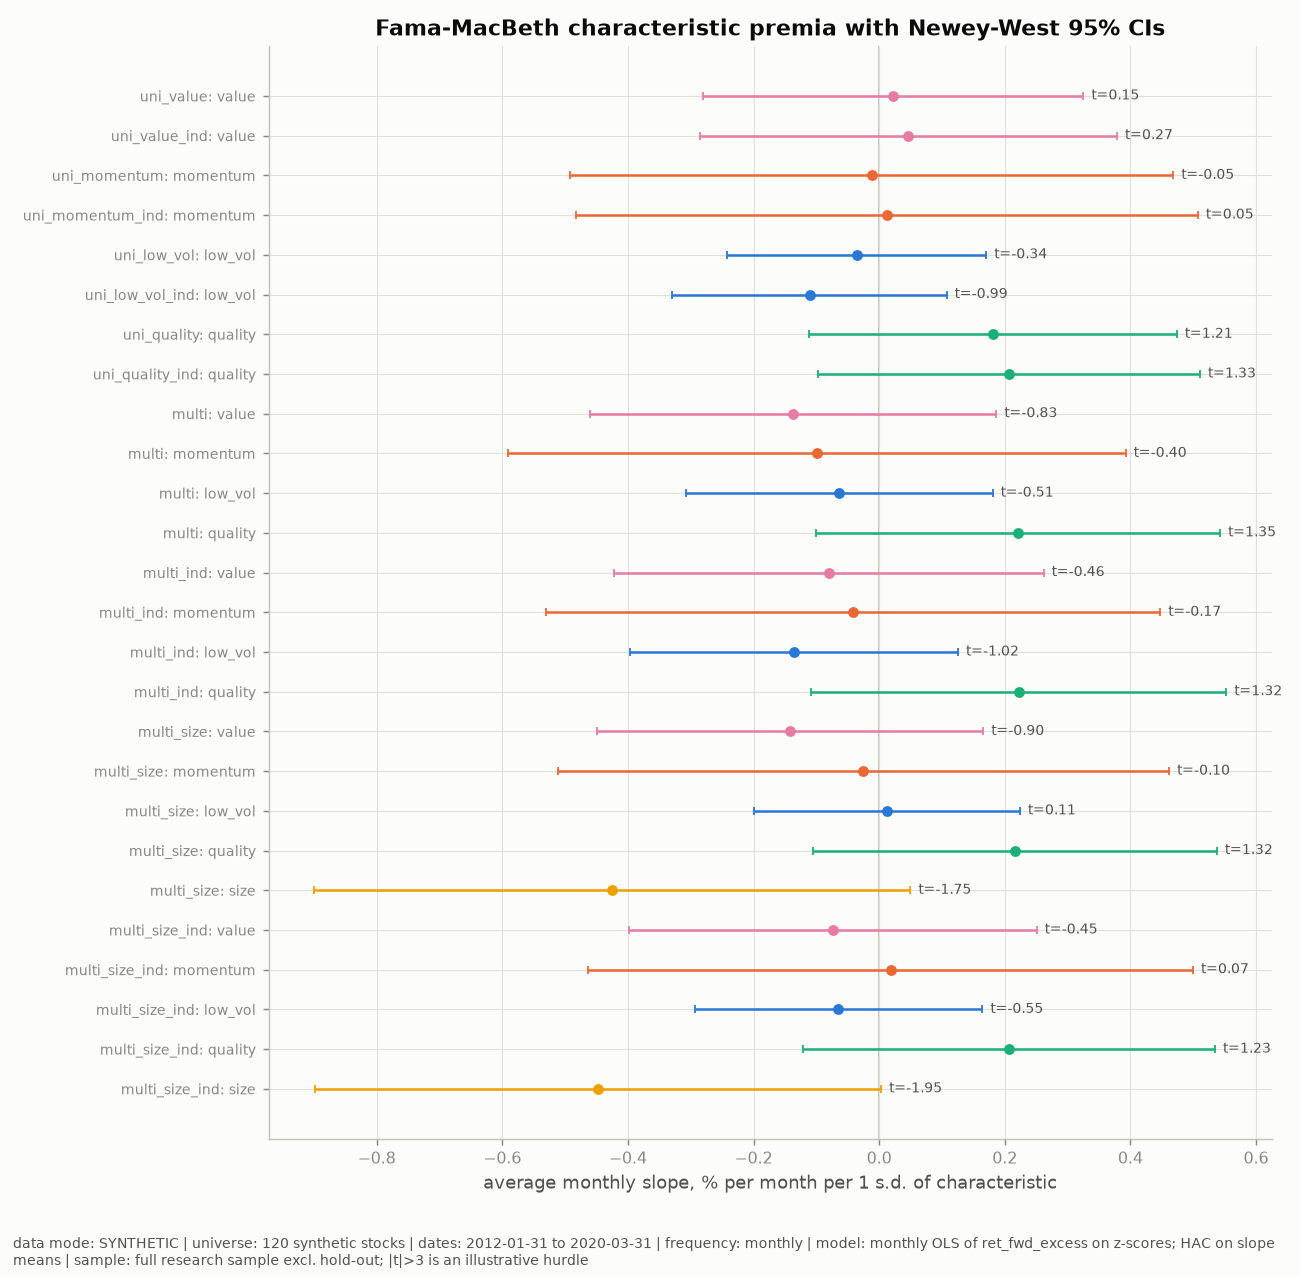

In [4]:
show(syn, '09', 'fama_macbeth_premia')

In [5]:
try:
    real = pl.Context('real')
    rr = pl.stage_fama_macbeth(real)
    display(rr['summary'][['spec', 'term', 'premium_monthly', 't_hac', 'n_months']].round(4))
except DataUnavailableError as e:
    print('REAL data not cached - skipped:', e)

,spec,term,premium_monthly,t_hac,n_months
0,uni_momentum,const,0.0124,4.6504,160
1,uni_momentum,momentum,0.0011,0.9406,160
2,uni_momentum_ind,const,0.0123,3.2285,160
3,uni_momentum_ind,momentum,0.0006,0.4739,160
4,uni_low_vol,const,0.0131,4.9073,166
5,uni_low_vol,low_vol,-0.0045,-2.6378,166
6,uni_low_vol_ind,const,0.0148,3.8618,166
7,uni_low_vol_ind,low_vol,-0.0041,-2.3832,166
